## ENERGY CONSUMPTION PREDICTION PROJECT

## Import Library

In [232]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

import joblib


##  LOAD DATASET


In [233]:
df = pd.read_csv("Energy_consumption.csv")


In [234]:
df.head()

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
0,2022-01-01 00:00:00,25.139433,43.431581,1565.693999,5,On,Off,2.774699,Monday,No,75.364373
1,2022-01-01 01:00:00,27.731651,54.225919,1411.064918,1,On,On,21.831384,Saturday,No,83.401855
2,2022-01-01 02:00:00,28.704277,58.907658,1755.715009,2,Off,Off,6.764672,Sunday,No,78.270888
3,2022-01-01 03:00:00,20.080469,50.371637,1452.316318,1,Off,On,8.623447,Wednesday,No,56.519850
4,2022-01-01 04:00:00,23.097359,51.401421,1094.130359,9,On,Off,3.071969,Friday,No,70.811732


In [235]:
df.shape

(1000, 11)

In [ ]:
df.info()   

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          1000 non-null   str    
 1   Temperature        1000 non-null   float64
 2   Humidity           1000 non-null   float64
 3   SquareFootage      1000 non-null   float64
 4   Occupancy          1000 non-null   int64  
 5   HVACUsage          1000 non-null   str    
 6   LightingUsage      1000 non-null   str    
 7   RenewableEnergy    1000 non-null   float64
 8   DayOfWeek          1000 non-null   str    
 9   Holiday            1000 non-null   str    
 10  EnergyConsumption  1000 non-null   float64
dtypes: float64(5), int64(1), str(5)
memory usage: 118.9 KB


In [237]:
df.describe()

,Temperature,Humidity,SquareFootage,Occupancy,RenewableEnergy,EnergyConsumption
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,24.982026,45.395412,1500.052488,4.581000,15.132813,77.055873
std,2.836850,8.518905,288.418873,2.865598,8.745917,8.144112
min,20.007565,30.015975,1000.512661,0.000000,0.006642,53.263278
25%,22.645070,38.297722,1247.108548,2.000000,7.628385,71.544690
50%,24.751637,45.972116,1507.967426,5.000000,15.072296,76.943696
75%,27.418174,52.420066,1740.340165,7.000000,22.884064,82.921742
max,29.998671,59.969085,1999.982252,9.000000,29.965327,99.201120


In [238]:
df.isnull().sum()

Timestamp            0
Temperature          0
Humidity             0
SquareFootage        0
Occupancy            0
HVACUsage            0
LightingUsage        0
RenewableEnergy      0
DayOfWeek            0
Holiday              0
EnergyConsumption    0
dtype: int64

In [239]:
df.duplicated().sum()

np.int64(0)

In [240]:
# Remove rows with missing target or timestamp values
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df = df.dropna(subset=["Timestamp", "EnergyConsumption"])
df = df.copy()

## EXPLORATORY DATA ANALYSIS (EDA)


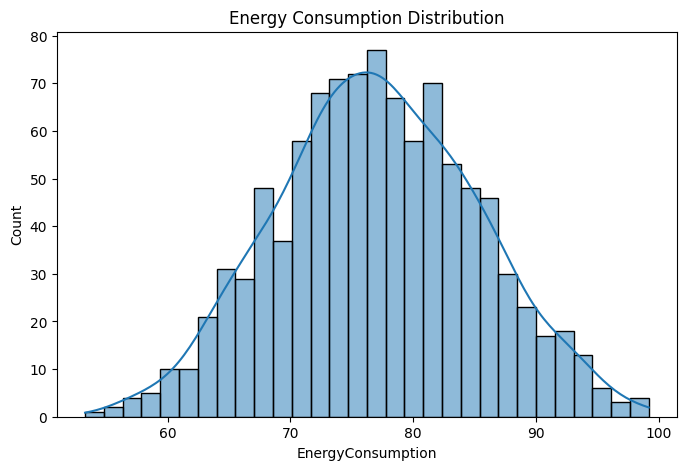

In [241]:
# Energy Consumption Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="EnergyConsumption", bins=30, kde=True)
plt.title("Energy Consumption Distribution")
plt.show()

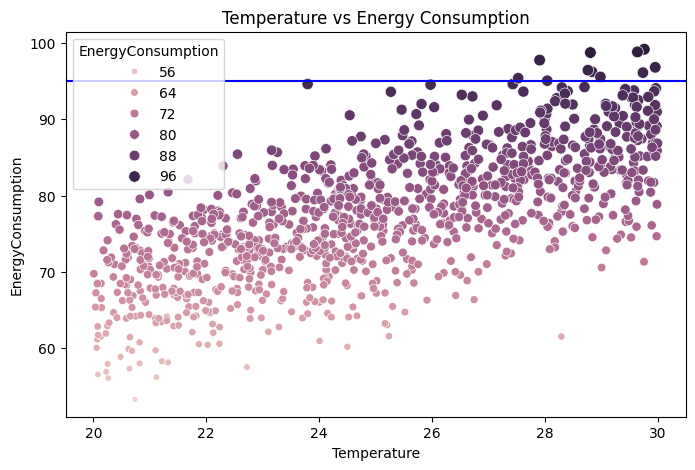

In [242]:
# Temperature vs Energy Consumption
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df,x="Temperature",y="EnergyConsumption",hue="EnergyConsumption",size ="EnergyConsumption")
plt.title("Temperature vs Energy Consumption")
plt.axhline(95,color="blue")
plt.show()

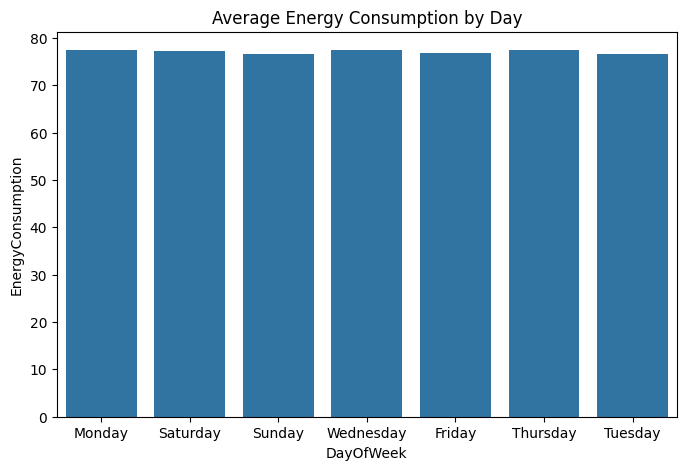

In [265]:
# Average Energy Consumption by Day
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df,
    x="DayOfWeek",
    y="EnergyConsumption",
    errorbar=None

)
plt.title("Average Energy Consumption by Day")
#plt.axhline(y=df["EnergyConsumption"].mean(), color="blue", linestyle="-")
plt.show()

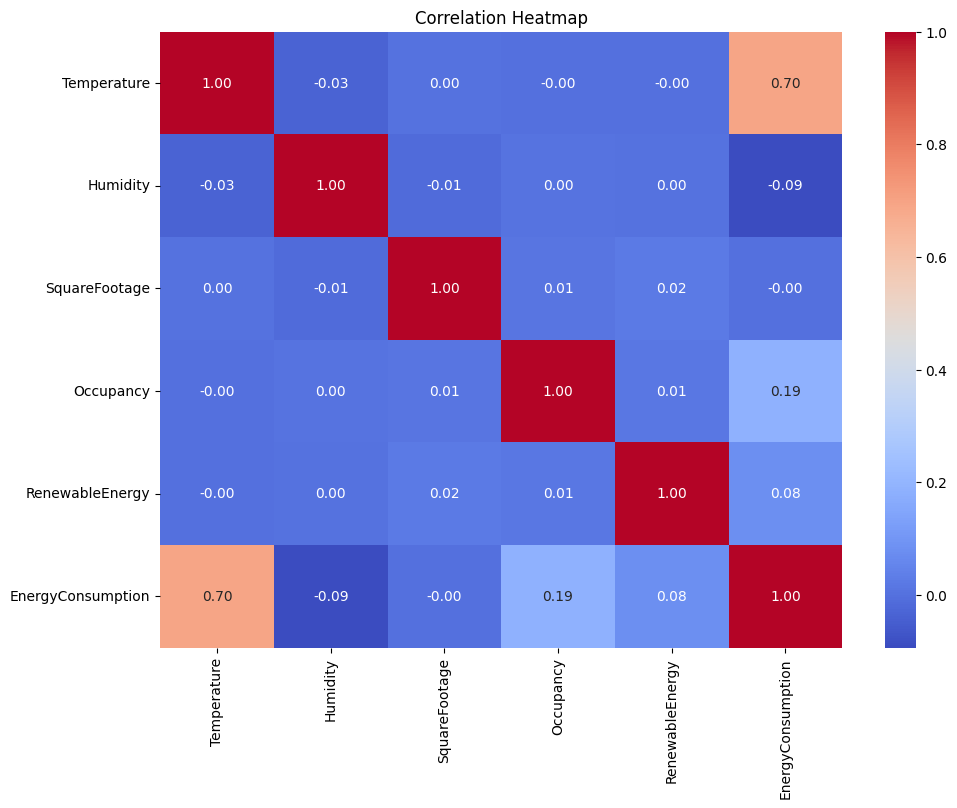

In [244]:
# Correlation Heatmap
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(11, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

## FEATURE ENGINEERING


In [245]:
df["Hour"] = df["Timestamp"].dt.hour
df["Day"] = df["Timestamp"].dt.day
df["Month"] = df["Timestamp"].dt.month

In [246]:
# Extract x and y
X = df.drop(columns=["EnergyConsumption", "Timestamp"])
y = df["EnergyConsumption"]

In [247]:
# Convert categorical columns to numeric columns
X = pd.get_dummies(X, dtype=int)

## TRAIN AND EVALUATE MODELS


In [248]:
# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 800
Testing rows: 200


In [249]:
# Random Forest Model
rf_model = RandomForestRegressor(n_estimators=100,random_state=42)

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

In [250]:
# Gradient Boosting Model
gb_model = GradientBoostingRegressor(n_estimators=100,random_state=42)

gb_model.fit(X_train, y_train)
gb_predictions = gb_model.predict(X_test)

In [251]:
# XGBoost Model
xgb_model = XGBRegressor(n_estimators=100,max_depth=4,learning_rate=0.1,random_state=42)

xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)

## MODEL EVALUATION


In [252]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

In [253]:
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

In [254]:
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

In [255]:
print("\nRANDOM FOREST RESULTS")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))


RANDOM FOREST RESULTS
MAE: 4.4
RMSE: 5.46
R2 Score: 0.5441


In [256]:
print("\nGRADIENT BOOSTING RESULTS")
print("MAE:", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))
print("R2 Score:", round(gb_r2, 4))


GRADIENT BOOSTING RESULTS
MAE: 4.33
RMSE: 5.45
R2 Score: 0.5467


In [257]:
print("\nXGBOOST RESULTS")
print("MAE:", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("R2 Score:", round(xgb_r2, 4))


XGBOOST RESULTS
MAE: 4.55
RMSE: 5.7
R2 Score: 0.5041


## MODEL COMPARISON


In [258]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "MAE": [
        rf_mae,
        gb_mae,
        xgb_mae
    ],
    "RMSE": [
        rf_rmse,
        gb_rmse,
        xgb_rmse
    ],
    "R2 Score": [
        rf_r2,
        gb_r2,
        xgb_r2
    ]
})

In [259]:
results = results.sort_values(by="MAE",ascending=True).reset_index(drop=True)

print("\nMODEL COMPARISON")
print(results.round(4))

results.to_csv("model_comparison.csv", index=False)


MODEL COMPARISON
               Model     MAE    RMSE  R2 Score
0  Gradient Boosting  4.3307  5.4492    0.5467
1      Random Forest  4.4023  5.4646    0.5441
2            XGBoost  4.5490  5.6990    0.5041


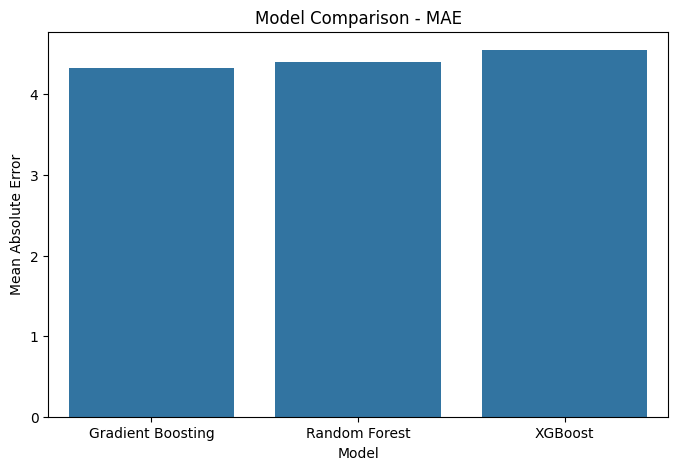

In [260]:
# Visualize model comparison
plt.figure(figsize=(8, 5))

sns.barplot(data=results,x="Model",y="MAE",errorbar=None)
plt.title("Model Comparison - MAE")
plt.ylabel("Mean Absolute Error")
plt.show()

## SAVE ALL TRAINED MODELS


In [261]:
joblib.dump(rf_model, "random_forest.pkl")
joblib.dump(gb_model, "gradient_boosting.pkl")
joblib.dump(xgb_model, "xgboost.pkl")

['xgboost.pkl']

In [262]:
# Select the model with the lowest MAE
trained_models = {
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

best_name = results.iloc[0]["Model"]
best_model = trained_models[best_name]

In [263]:
joblib.dump(best_model, "best_model.pkl")

['best_model.pkl']

In [264]:
print("\nBEST MODEL:", best_name)
print("Best MAE:", round(results.iloc[0]["MAE"], 2))


BEST MODEL: Gradient Boosting
Best MAE: 4.33
